# India Air Quality: Next-Day Category Prediction with Random Forest

**Model:** Random Forest classifier. The target is one of six categories, so this is classification. Regression would instead predict a numeric AQI value and require different targets and metrics.

Predict a city's **next calendar day's air-quality category** using information available at the end of today. This notebook adapts the supplied reference into a portable, reproducible project with data checks, exploratory analysis, date-aware features, chronological model selection, a persistence baseline, and saved results.

### Run in VS Code or Google Colab
1. Keep this notebook and `aqi.csv` in the same folder (a `data/` subfolder also works). In Colab, upload both files to the session.
2. If needed, run the installation line in the next cell once, then restart your kernel.
3. Choose **Run All**. No API key or external data download is required. Model fitting may take several minutes on a laptop.

The executed outputs below use the supplied CSV. The reference's filename mentions 2023–2025, but dates are measured directly from the file. No external provenance or license claims have been independently verified.


In [13]:
# Uncomment only if these packages are missing in your selected notebook kernel.
# %pip install pandas numpy matplotlib scikit-learn joblib threadpoolctl
from pathlib import Path
import json, hashlib, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42 # Limits CPU contention; all eligible records are retained.
OUTPUT_DIR = Path.cwd() / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)


Python: 3.14.6 | scikit-learn: 1.9.1


## 1. Load and audit the dataset
Paths are relative so the project can run on another laptop. We require the expected columns and parse the day-first date format explicitly. A location is identified by **state + area**, not just area name.


In [3]:
candidates =Path.cwd()/'aqi.csv'
DATA_PATH = candidates
if DATA_PATH is None:
    raise FileNotFoundError('Place aqi.csv beside this notebook or inside data/, then Run All.')
raw = pd.read_csv(DATA_PATH)
required = ['date', 'state', 'area', 'aqi_value', 'air_quality_status',
            'number_of_monitoring_stations', 'prominent_pollutants']
assert set(required).issubset(raw.columns), f'Missing columns: {set(required)-set(raw.columns)}'
print(f'Raw dataset: {len(raw):,} rows, {raw.shape[1]} columns')
print(raw.head().to_string(index=False))
audit = pd.DataFrame({'type': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
                      'unique': raw.nunique()})
print('\nColumn audit:\n', audit.to_string())


Raw dataset: 235,785 rows, 9 columns
      date          state     area  number_of_monitoring_stations prominent_pollutants  aqi_value air_quality_status                                                                   unit  note
30-04-2025    Maharashtra Amravati                              2                 PM10         78       Satisfactory number_of_monitoring_stations in Absolute Number, aqi_value in Indices   NaN
30-04-2025          Bihar   Purnia                              1                   CO         56       Satisfactory number_of_monitoring_stations in Absolute Number, aqi_value in Indices   NaN
30-04-2025 Madhya Pradesh    Katni                              1                   O3         98       Satisfactory number_of_monitoring_stations in Absolute Number, aqi_value in Indices   NaN
30-04-2025   Chhattisgarh  Tumidih                              1                 PM10        103           Moderate number_of_monitoring_stations in Absolute Number, aqi_value in Indices

## 2. Clean records and check category consistency
Remove exact duplicates first. Invalid dates, missing location names, and AQI outside 0–500 are excluded. If conflicting records remain for the same city-day, exclude that city-day rather than arbitrarily selecting one. Missing monitoring-station counts remain missing; missing values are filled using training-set medians inside the model pipeline.

The target uses the category supplied in the CSV. The check below compares it with the six conventional AQI bands used in the reference. Unexpected or inconsistent labels are excluded and counted.


In [4]:
LEVELS = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
KEYS = ['state', 'area']
df = raw.drop_duplicates().copy()
exact_removed = len(raw) - len(df)
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y', errors='coerce')
for col in KEYS + ['air_quality_status']:
    df[col] = df[col].astype('string').str.strip()
for col in ['aqi_value', 'number_of_monitoring_stations']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
valid = (df['date'].notna() & df['aqi_value'].between(0, 500)
         & df[KEYS].notna().all(axis=1) & df[KEYS].ne('').all(axis=1))
invalid_removed = int((~valid).sum())
df = df.loc[valid].copy()
conflicts = df.duplicated(KEYS + ['date'], keep=False)
conflict_removed = int(conflicts.sum())
df = df.loc[~conflicts].copy()
expected = pd.cut(df['aqi_value'], [-np.inf, 50, 100, 200, 300, 400, np.inf], labels=LEVELS).astype('string')
consistent = df['air_quality_status'].eq(expected).fillna(False)
label_removed = int((~consistent).sum())
df = df.loc[consistent].copy()
df.loc[df['number_of_monitoring_stations'] < 0, 'number_of_monitoring_stations'] = np.nan
df = df.sort_values(KEYS + ['date']).reset_index(drop=True)
assert not df.duplicated(KEYS + ['date']).any()
print({'exact_duplicates_removed': exact_removed, 'invalid_rows_removed': invalid_removed,
       'conflicting_city_day_rows_removed': conflict_removed, 'label_mismatches_removed': label_removed})
print(f'Clean: {len(df):,} records; {df[KEYS].drop_duplicates().shape[0]} locations; {df.state.nunique()} states')
print('Actual date range:', df.date.min().date(), 'to', df.date.max().date())


{'exact_duplicates_removed': 0, 'invalid_rows_removed': 0, 'conflicting_city_day_rows_removed': 0, 'label_mismatches_removed': 1}
Clean: 235,784 records; 292 locations; 32 states
Actual date range: 2022-04-01 to 2025-04-30


## 3. Explore air quality
These are descriptive summaries of available observations. The daily mean is an **unweighted mean across reporting locations**, not a population-weighted national exposure measure. Changes in reporting coverage may affect it. City rankings below require at least 180 records but may still cover different dates.


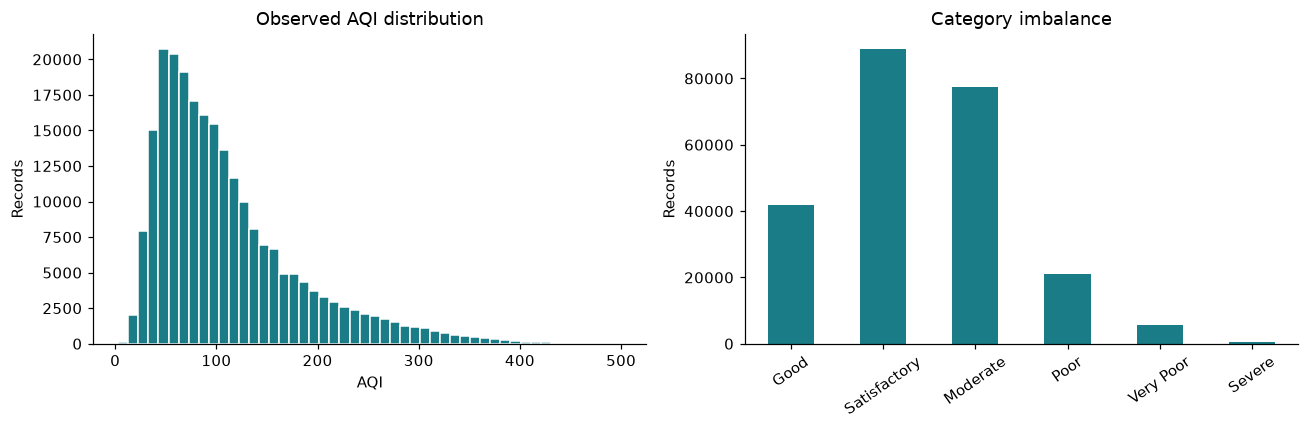

air_quality_status
Good            41971
Satisfactory    88897
Moderate        77537
Poor            21154
Very Poor        5671
Severe            554


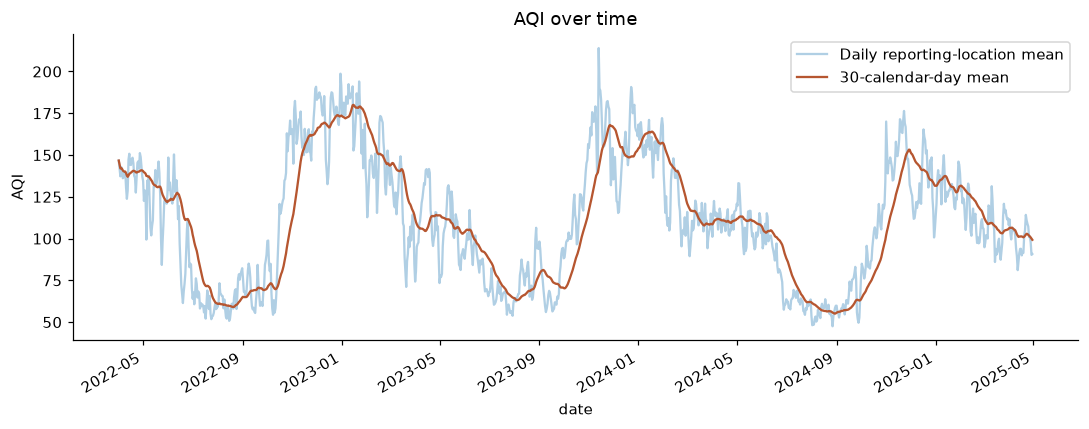

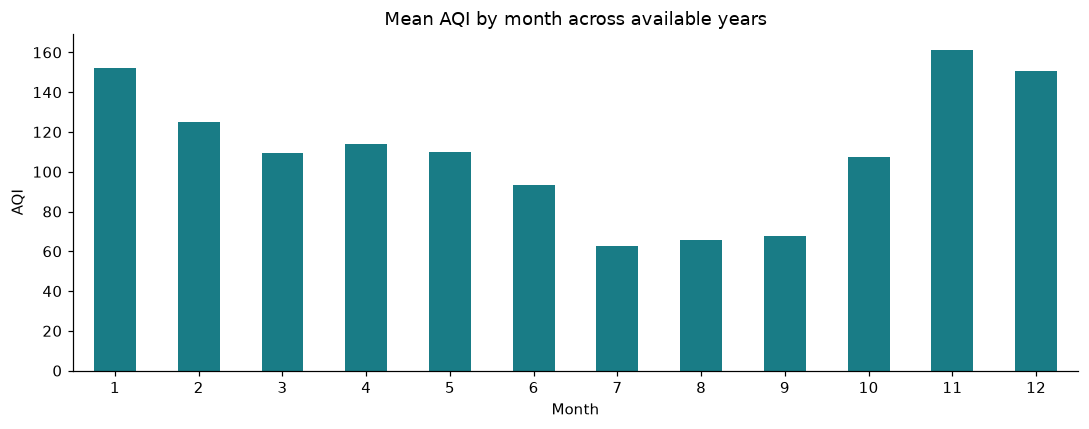

Highest mean AQI locations (minimum 180 records):
                                mean  count
state         area                         
Assam         Byrnihat        240.00    656
Bihar         Begusarai       206.68    582
Delhi         Delhi           206.25   1124
Uttar Pradesh Greater Noida   201.60   1123
Rajasthan     Sri Ganganagar  197.94    709
Haryana       Gurugram        190.85   1120
Bihar         Darbhanga       190.09    256
Haryana       Dharuhera       185.72    764
Uttar Pradesh NOIDA           183.99   1124
              Ghaziabad       183.01   1124


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df.aqi_value, bins=50, color='#197c86', edgecolor='white')
axes[0].set(title='Observed AQI distribution', xlabel='AQI', ylabel='Records')
counts = df.air_quality_status.value_counts().reindex(LEVELS, fill_value=0)
counts.plot.bar(ax=axes[1], color='#197c86', rot=35)
axes[1].set(title='Category imbalance', ylabel='Records', xlabel='')
plt.tight_layout(); plt.show()
print(counts.to_string())
trend = df.groupby('date').aqi_value.mean()
trend.plot(alpha=.35, label='Daily reporting-location mean')
trend.rolling('30D').mean().plot(label='30-calendar-day mean', color='#b65630')
plt.title('AQI over time'); plt.ylabel('AQI'); plt.legend(); plt.tight_layout(); plt.show()
monthly = df.groupby(df.date.dt.month).aqi_value.mean()
monthly.plot.bar(color='#197c86', rot=0)
plt.title('Mean AQI by month across available years'); plt.xlabel('Month'); plt.ylabel('AQI')
plt.tight_layout(); plt.show()
city_stats = df.groupby(KEYS).aqi_value.agg(['mean', 'count']).query('count >= 180').sort_values('mean', ascending=False)
print('Highest mean AQI locations (minimum 180 records):')
print(city_stats.head(10).round(2).to_string())


## 4. Build strictly date-aware features and tomorrow's target
**Prediction time:** end of day t, once today's AQI and station count are published. Predict the category on t+1. This is a daily rolling forecast, not a forecast of the whole future period made in advance.

Exact calendar joins create lags at t−1, t−3 and t−7. Rolling means use only observations in the preceding 7 or 14 calendar days and exclude today. Missing dates stay missing; they are never filled from future observations. The target is joined at exactly t+1, so a gap cannot silently become a next-day example.

Today's category is excluded from model features (today's AQI already conveys its band). Pollutant names are omitted for a compact numeric model. No future AQI or future station counts are features.


In [7]:
def make_features(history):
    out = history.sort_values(KEYS + ['date']).copy()
    for lag in [1, 3, 7]:
        past = history[KEYS + ['date', 'aqi_value']].copy()
        past['date'] += pd.Timedelta(days=lag)
        past = past.rename(columns={'aqi_value': f'aqi_lag{lag}'})
        out = out.merge(past, on=KEYS + ['date'], how='left', validate='one_to_one')
    out = out.sort_values(KEYS + ['date']).reset_index(drop=True)
    for _, group in out.groupby(KEYS, sort=False):
        values = group.set_index('date')['aqi_value']
        for days in [7, 14]:
            roll = values.rolling(f'{days}D', closed='left', min_periods=2)
            out.loc[group.index, f'aqi_mean{days}'] = roll.mean().to_numpy()
        out.loc[group.index, 'aqi_std7'] = values.rolling('7D', closed='left', min_periods=2).std().to_numpy()
    tomorrow = out['date'] + pd.Timedelta(days=1)
    out['month_sin'] = np.sin(2*np.pi*tomorrow.dt.month/12)
    out['month_cos'] = np.cos(2*np.pi*tomorrow.dt.month/12)
    out['weekday'] = tomorrow.dt.dayofweek
    return out

FEATURES = ['aqi_value', 'number_of_monitoring_stations', 'aqi_lag1', 'aqi_lag3',
            'aqi_lag7', 'aqi_mean7', 'aqi_mean14', 'aqi_std7', 'month_sin', 'month_cos', 'weekday']
feature_panel = make_features(df)
future = df[KEYS + ['date', 'air_quality_status']].rename(columns={'date':'target_date', 'air_quality_status':'target_label'})
future['date'] = future['target_date'] - pd.Timedelta(days=1)
data = feature_panel.merge(future, on=KEYS + ['date'], how='inner', validate='one_to_one')
label_to_code = {name: i for i, name in enumerate(LEVELS)}
data['target'] = data.target_label.map(label_to_code).astype(int)
data['baseline'] = data.air_quality_status.map(label_to_code).astype(int)
assert (data.target_date - data.date).eq(pd.Timedelta(days=1)).all()
assert not any(c in FEATURES for c in ['target', 'target_label', 'target_date'])
print(f'Eligible exact-next-day pairs: {len(data):,}')
print(f'Records without an observed next day: {len(df)-len(data):,}')


C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\2697353587.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past['date'] += pd.Timedelta(days=lag)
C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\2697353587.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past['date'] += pd.Timedelta(days=lag)
C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\2697353587.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past['date'] += pd.Timedelta(days=lag)
C:\Users\DELL\AppData\Local\Temp\ipykern

Eligible exact-next-day pairs: 220,419
Records without an observed next day: 15,365


C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\2697353587.py:30: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert (data.target_date - data.date).eq(pd.Timedelta(days=1)).all()


## 5. Chronological training, validation and test sets
The latest **90 target dates** form the untouched test period; the preceding **60 target dates** form validation. Older targets train candidate models. Splitting by target date keeps every city on a given target day in the same partition.

We compare three small parameter configurations on validation macro F1, which gives each of the six categories equal weight. This is chronological holdout tuning, **not cross-validation**. Each forest averages the votes of many decision trees. We tune tree count (`n_estimators`), maximum depth (`max_depth`), and minimum leaf size (`min_samples_leaf`). Each tree uses a bootstrap sample of 70% of the training rows; all eligible records remain in the chronological splits. Median imputation is fitted only on the training partition through a pipeline. After selection, refit using train + validation and evaluate the final test period once. Previous observed test-day AQI may be used for later test-day forecasts, as it would be available in daily operation.


In [8]:
last_target = data.target_date.max()
test_start = last_target - pd.Timedelta(days=89)
validation_start = test_start - pd.Timedelta(days=60)
train = data.loc[data.target_date < validation_start].copy()
validation = data.loc[data.target_date.between(validation_start, test_start, inclusive='left')].copy()
test = data.loc[data.target_date >= test_start].copy()
assert min(len(train), len(validation), len(test)) > 0
assert train.target_date.max() < validation.target_date.min() <= validation.target_date.max() < test.target_date.min()
assert set(train.target.unique()) == set(range(6)), 'Training period must contain all six classes.'
for name, part in [('Train', train), ('Validation', validation), ('Test', test)]:
    print(f'{name:10s}: {len(part):,} pairs | target dates {part.target_date.min().date()} to {part.target_date.max().date()}')
print('\nClass support by split:')
print(pd.DataFrame({name: part.target_label.value_counts().reindex(LEVELS, fill_value=0)
                    for name, part in [('train', train), ('validation', validation), ('test', test)]}).to_string())


Train     : 188,011 pairs | target dates 2022-04-02 to 2024-12-01
Validation: 13,114 pairs | target dates 2024-12-02 to 2025-01-30
Test      : 19,294 pairs | target dates 2025-01-31 to 2025-04-30

Class support by split:
              train  validation  test
target_label                         
Good          35554        1065  1854
Satisfactory  70855        3847  8121
Moderate      58880        6067  8289
Poor          17217        1844   964
Very Poor      5011         278    64
Severe          494          13     2


C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\1418551530.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  test_start = last_target - pd.Timedelta(days=89)
C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\1418551530.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  validation_start = test_start - pd.Timedelta(days=60)


In [14]:

# Earlier notebook cells must already define:
# train, validation, FEATURES, LEVELS, SEED, OUTPUT_DIR
# pd, np, Pipeline, SimpleImputer, RandomForestClassifier, f1_score

N_ITER = 6  # Increase later if runtime permits.

# 1. Sort training observations chronologically.
cv_data = (
    train.sort_values(["target_date", "state", "area"])
    .reset_index(drop=True)
)

X_cv = cv_data[FEATURES]
y_cv = cv_data["target"]

# Split a complete calendar, then map dates back to observation rows.
# This keeps every location on a given target date in the same fold.
calendar = pd.date_range(
    cv_data["target_date"].min(),
    cv_data["target_date"].max(),
    freq="D",
)

date_splitter = TimeSeriesSplit(n_splits=5)
cv_splits = []
fold_rows = []

for fold, (train_days, valid_days) in enumerate(
    date_splitter.split(calendar), start=1
):
    training_dates = calendar[train_days]
    validation_dates = calendar[valid_days]

    train_idx = np.flatnonzero(
        cv_data["target_date"].isin(training_dates).to_numpy()
    )
    valid_idx = np.flatnonzero(
        cv_data["target_date"].isin(validation_dates).to_numpy()
    )

    if len(train_idx) == 0 or len(valid_idx) == 0:
        raise ValueError(f"Fold {fold} has an empty partition.")

    train_end = cv_data.iloc[train_idx]["target_date"].max()
    valid_start = cv_data.iloc[valid_idx]["target_date"].min()
    assert train_end < valid_start

    cv_splits.append((train_idx, valid_idx))

    baseline_f1 = f1_score(
        y_cv.iloc[valid_idx],
        cv_data.iloc[valid_idx]["baseline"],
        labels=list(range(len(LEVELS))),
        average="macro",
        zero_division=0,
    )

    fold_rows.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "validation_rows": len(valid_idx),
        "train_end": str(train_end.date()),
        "validation_start": str(valid_start.date()),
        "validation_end": str(
            cv_data.iloc[valid_idx]["target_date"].max().date()
        ),
        "persistence_macro_f1": baseline_f1,
    })

fold_summary = pd.DataFrame(fold_rows)
print("Chronological folds:")
print(fold_summary.to_string(index=False))


# 2. Define a pipeline compatible with the notebook's later cells.
def build_model(params):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("forest", RandomForestClassifier(
            **params,
            max_features="sqrt",
            bootstrap=True,
            max_samples=0.7,
            n_jobs=2,
            random_state=SEED,
        )),
    ])


# Pipeline parameters use component_name__parameter_name.
param_distributions = {
    "forest__n_estimators": [60, 80, 120],
    "forest__max_depth": [12, 16, 20],
    "forest__min_samples_leaf": [3, 5, 10],
    "forest__class_weight": [None, "balanced_subsample"],
}

# Fixed six-class macro F1 matches your existing evaluation.
macro_f1_scorer = make_scorer(
    f1_score,
    labels=list(range(len(LEVELS))),
    average="macro",
    zero_division=0,
)

search = RandomizedSearchCV(
    estimator=build_model({}),
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring=macro_f1_scorer,
    cv=cv_splits,
    refit=True,
    random_state=SEED,
    n_jobs=1,  # Forest uses 2 workers; avoid nested parallelism.
    verbose=2,
    return_train_score=False,
    error_score="raise",
)

search.fit(X_cv, y_cv)


# 3. Preserve variable names required by later notebook cells.
best_params = {
    key.replace("forest__", "", 1): value
    for key, value in search.best_params_.items()
}

search_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

columns_to_show = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "params",
]

print("\nRandomized-search results:")
print(search_results[columns_to_show].to_string(index=False))
print("\nSelected parameters:", best_params)
print(f"Best mean CV macro F1: {search.best_score_:.4f}")
print(
    "Mean persistence CV macro F1:",
    f"{fold_summary['persistence_macro_f1'].mean():.4f}",
)

# Add the selected configuration's score on each CV fold.
# These fold scores participated in model selection.
for fold_index in range(len(cv_splits)):
    fold_summary.loc[
        fold_index, "selected_rf_macro_f1"
    ] = search.cv_results_[
        f"split{fold_index}_test_score"
    ][search.best_index_]


# 4. Evaluate on the existing separate 60-day validation period.
# best_estimator_ has been refitted on cv_data (training only).
validation_predictions = search.best_estimator_.predict(
    validation[FEATURES]
)

validation_model_f1 = f1_score(
    validation["target"],
    validation_predictions,
    labels=list(range(len(LEVELS))),
    average="macro",
    zero_division=0,
)

validation_baseline = f1_score(
    validation["target"],
    validation["baseline"],
    labels=list(range(len(LEVELS))),
    average="macro",
    zero_division=0,
)

preferred = (
    "Random Forest"
    if validation_model_f1 > validation_baseline
    else "Persistence"
)

print(f"\nValidation Random Forest macro F1: {validation_model_f1:.4f}")
print(f"Validation persistence macro F1:   {validation_baseline:.4f}")
print("Preferred approach using validation only:", preferred)


# 5. Save search evidence.
OUTPUT_DIR.mkdir(exist_ok=True)

search_results.to_csv(
    OUTPUT_DIR / "randomized_search_cv_results.csv",
    index=False,
)
fold_summary.to_csv(
    OUTPUT_DIR / "chronological_cv_folds.csv",
    index=False,
)

print("\nSearch results and fold details saved.")
print("Next: run the remaining evaluation and export cells.")

Chronological folds:
 fold  train_rows  validation_rows  train_end validation_start validation_end  persistence_macro_f1
    1       22896            26701 2022-09-13       2022-09-14     2023-02-22              0.661104
    2       49597            30767 2023-02-22       2023-02-23     2023-08-03              0.572636
    3       80364            34880 2023-08-03       2023-08-04     2024-01-12              0.655125
    4      115244            36320 2024-01-12       2024-01-13     2024-06-22              0.546838
    5      151564            36447 2024-06-22       2024-06-23     2024-12-01              0.597748
Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END forest__class_weight=None, forest__max_depth=20, forest__min_samples_leaf=3, forest__n_estimators=80; total time=   1.4s
[CV] END forest__class_weight=None, forest__max_depth=20, forest__min_samples_leaf=3, forest__n_estimators=80; total time=   2.6s
[CV] END forest__class_weight=None, forest__max_depth=20, f

## 6. Final evaluation against persistence
Persistence predicts tomorrow's category equals today's. A complex model is useful only if the measured result justifies it. Macro F1 is computed across all six fixed classes (absent classes receive zero); also inspect support and individual recalls. Accuracy alone can conceal weak detection of rare categories.

The severe-class test count may be very small. This single time window does not establish year-round reliability, health benefits, or financial impact.


     approach  accuracy  macro_f1  weighted_f1  balanced_accuracy
  Persistence    0.7298    0.4887       0.7300             0.4921
Random Forest    0.7336    0.5026       0.7347             0.5082

Random Forest classification report:
              precision    recall  f1-score   support

        Good     0.7259    0.6899    0.7074      1854
Satisfactory     0.7660    0.7213    0.7430      8121
    Moderate     0.7488    0.7808    0.7645      8289
        Poor     0.4464    0.5446    0.4907       964
   Very Poor     0.3077    0.3125    0.3101        64
      Severe     0.0000    0.0000    0.0000         2

    accuracy                         0.7336     19294
   macro avg     0.4991    0.5082    0.5026     19294
weighted avg     0.7372    0.7336    0.7347     19294

Model minus persistence macro F1: +0.0139 (+1.39 percentage points)
Validation-selected approach: Persistence


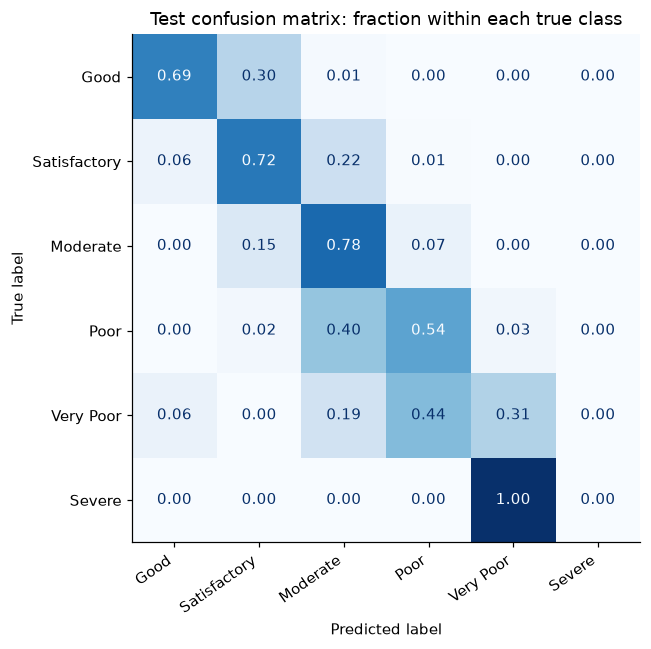

In [15]:
development = pd.concat([train, validation], ignore_index=True)
model = build_model(best_params)
model.fit(development[FEATURES], development.target)
pred_model = model.predict(test[FEATURES])
pred_baseline = test.baseline.to_numpy()
def summarize(name, predicted):
    return {'approach':name, 'accuracy':accuracy_score(test.target, predicted),
            'macro_f1':f1_score(test.target, predicted, labels=range(6), average='macro', zero_division=0),
            'weighted_f1':f1_score(test.target, predicted, labels=range(6), average='weighted', zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(test.target, predicted)}
metrics = pd.DataFrame([summarize('Persistence', pred_baseline), summarize('Random Forest', pred_model)])
print(metrics.round(4).to_string(index=False))
print('\nRandom Forest classification report:')
print(classification_report(test.target, pred_model, labels=range(6), target_names=LEVELS, zero_division=0, digits=4))
delta = metrics.iloc[1].macro_f1 - metrics.iloc[0].macro_f1
print(f'Model minus persistence macro F1: {delta:+.4f} ({delta*100:+.2f} percentage points)')
print('Validation-selected approach:', preferred)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(test.target, pred_model, labels=range(6), display_labels=LEVELS,
                                       normalize='true', values_format='.2f', cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Test confusion matrix: fraction within each true class')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()


## 7. Inspect errors and produce a forecast
The examples show the largest category mistakes. The forecast function uses only observations up to the requested date and requires that day's AQI. Its numeric probability is an **uncalibrated model score**, not a guarantee. The default example forecasts the day after the file ends; no observed outcome is available for that future date. This is a demonstration for locations in this dataset, not a validated service for unseen cities.


In [16]:
predictions = test[KEYS + ['date', 'target_date', 'aqi_value', 'target_label']].copy()
predictions['model_prediction'] = [LEVELS[i] for i in pred_model]
predictions['baseline_prediction'] = [LEVELS[i] for i in pred_baseline]
predictions['category_distance'] = np.abs(test.target.to_numpy() - pred_model)
print(predictions.sort_values('category_distance', ascending=False).head(10).to_string(index=False))

def forecast_next_day(state, area, as_of=None):
    history = df.loc[df.state.eq(state) & df.area.eq(area)].copy()
    if history.empty:
        raise ValueError('Location not found; use state and area names from the CSV.')
    date = history.date.max() if as_of is None else pd.Timestamp(as_of)
    if date < development.target_date.max():
        raise ValueError('Use a date on or after the training target cutoff for this fitted model.')
    history = history.loc[history.date <= date]
    if not history.date.eq(date).any():
        raise ValueError('No AQI observation exists for the requested date.')
    row = make_features(history).loc[lambda x: x.date.eq(date)]
    probs = model.predict_proba(row[FEATURES])[0]
    idx = int(np.argmax(probs))
    return {'state':state, 'area':area, 'forecast_for':str((date+pd.Timedelta(days=1)).date()),
            'model_category':LEVELS[int(model.classes_[idx])],
            'uncalibrated_model_score':round(float(probs[idx]), 4),
            'persistence_category':str(row.air_quality_status.iloc[0])}
example = df.loc[df.date.eq(df.date.max())].iloc[0]
print('\nExample forecast:', forecast_next_day(example.state, example.area))


      state            area       date target_date  aqi_value target_label model_prediction baseline_prediction  category_distance
    Tripura        Agartala 2025-04-22  2025-04-23        312    Very Poor             Good           Very Poor                  4
    Tripura        Agartala 2025-04-04  2025-04-05         36    Very Poor             Good                Good                  4
    Tripura        Agartala 2025-04-24  2025-04-25        339         Good        Very Poor           Very Poor                  4
    Tripura        Agartala 2025-04-21  2025-04-22         23    Very Poor             Good                Good                  4
    Tripura        Agartala 2025-04-26  2025-04-27         24    Very Poor             Good                Good                  4
 Tamil Nadu        Ariyalur 2025-03-05  2025-03-06         34         Poor             Good                Good                  3
      Bihar      Samastipur 2025-03-05  2025-03-06        224         Good         

C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\2697353587.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past['date'] += pd.Timedelta(days=lag)
C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\2697353587.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past['date'] += pd.Timedelta(days=lag)
C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\2697353587.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past['date'] += pd.Timedelta(days=lag)
C:\Users\DELL\AppData\Local\Temp\ipykern


Example forecast: {'state': 'Andhra Pradesh', 'area': 'Amaravati', 'forecast_for': '2025-05-01', 'model_category': 'Satisfactory', 'uncalibrated_model_score': 0.8132, 'persistence_category': 'Satisfactory'}


C:\Users\DELL\AppData\Local\Temp\ipykernel_5036\3873005680.py:20: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  return {'state':state, 'area':area, 'forecast_for':str((date+pd.Timedelta(days=1)).date()),


## 8. Export reproducible project results
Running this cell creates an `outputs/` folder with metrics, parameter-search results, predictions, a trained estimator, run details and a factual resume bullet. The saved estimator expects the exact engineered features listed in its bundle; use the feature-building function above for inference. Only load joblib files you trust.

The resume text reports measured predictive performance and baseline comparison. It does not claim deployment, money saved, or improvements in public health.


In [20]:
metrics.to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)
search_results.to_csv(OUTPUT_DIR / 'validation_search.csv', index=False)
predictions.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
joblib.dump({'model': model, 'features': FEATURES, 'levels': LEVELS,
             'training_target_end': str(development.target_date.max().date())}, OUTPUT_DIR / 'aqi_model.joblib')
config = {'seed': SEED, 'features': FEATURES, 'selected_parameters': best_params,
          'validation_selected_approach': preferred, 'raw_records':len(raw), 'clean_records':len(df),
          'eligible_pairs':len(data), 'test_pairs':len(test),
          'validation_start':str(validation_start.date()), 'test_start':str(test_start.date()),
          'test_end':str(last_target.date()), 'sklearn_version':sklearn.__version__,
          'pandas_version':pd.__version__, 'numpy_version':np.__version__,
          'dataset_sha256':hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}
(OUTPUT_DIR / 'run_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
print('\nGenerated files:', ', '.join(p.name for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()))



Generated files: aqi_model.joblib, chronological_cv_folds.csv, randomized_search_cv_results.csv, resume_bullet.txt, run_config.json, test_metrics.csv, test_predictions.csv, validation_search.csv
